# Project 2

Dana Sela

### Part 1: Loading and Visualizing the EEG Signal

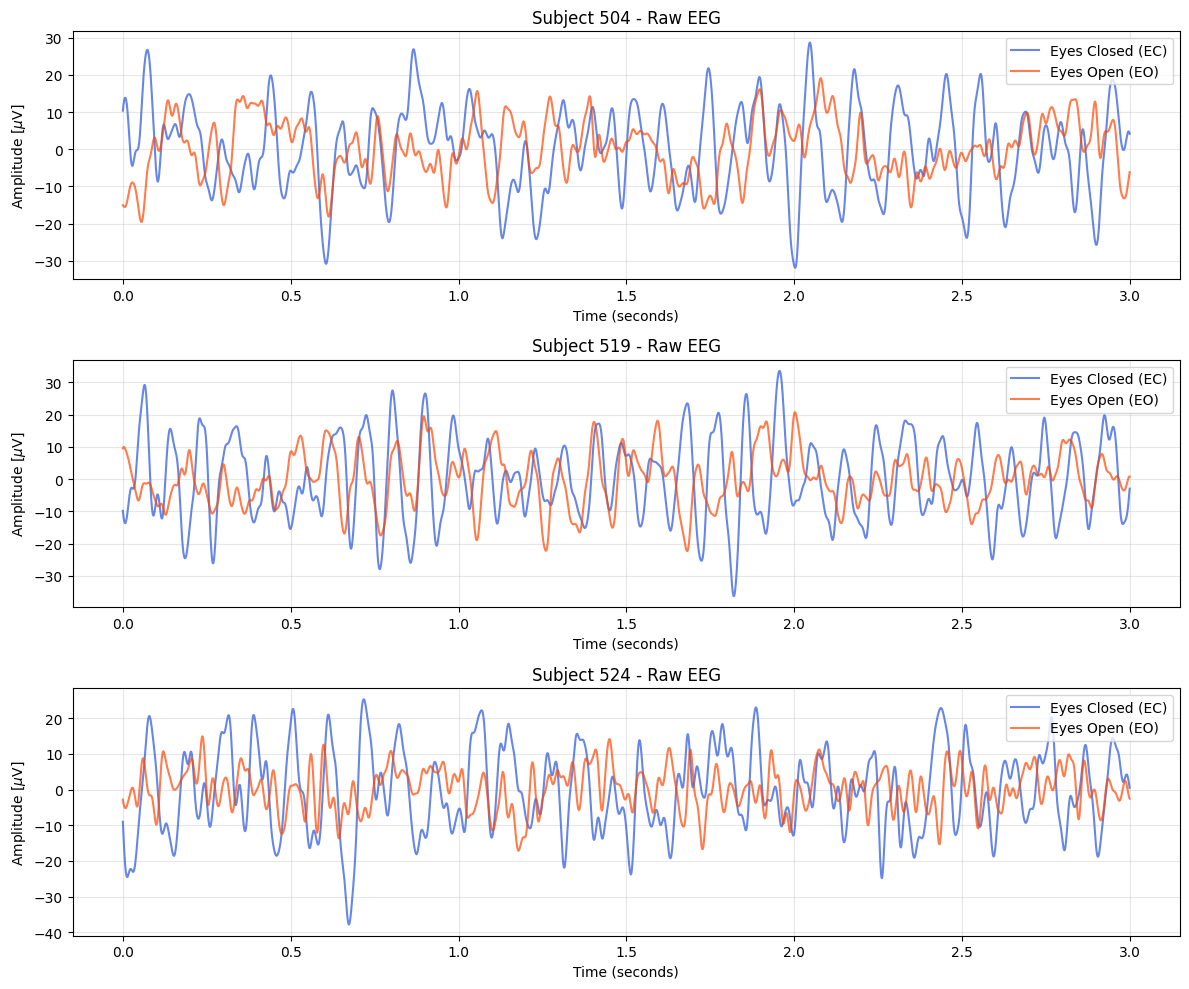

In [23]:
# Prepping the system.
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

# Variables for sampling frequency, a time vector, and a time window.
fs = 1024
t = np.arange(0, 40, 1/fs)
window_3s = int(3 * fs)

# List of subjects.
subjects = ['504', '519', '524']
data = {}

# A loop to load and extract data for each participant.
for sub in subjects:
  file_path = f'/content/drive/MyDrive/Signal Processing/Project #2/subject_{sub}.csv'
  df = pd.read_csv(file_path)
  data[sub] = {
      'EC': df['EC'].values,
      'EO': df['EO'].values
  }

# Plotting all 3 graphs.
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

for i, sub in enumerate(subjects):
    axes[i].plot(t[:window_3s], data[sub]['EC'][:window_3s], label='Eyes Closed (EC)', color='royalblue', alpha=0.8)
    axes[i].plot(t[:window_3s], data[sub]['EO'][:window_3s], label='Eyes Open (EO)', color='orangered', alpha=0.7)

    axes[i].set_title(f'Subject {sub} - Raw EEG')
    axes[i].set_xlabel('Time (seconds)')
    axes[i].set_ylabel(r'Amplitude [$\mu$V]')
    axes[i].grid(True, alpha=0.3)
    axes[i].legend(loc='upper right')

plt.tight_layout()
plt.show()

### Part 2: Band-Pass Filtering (2-40 Hz)

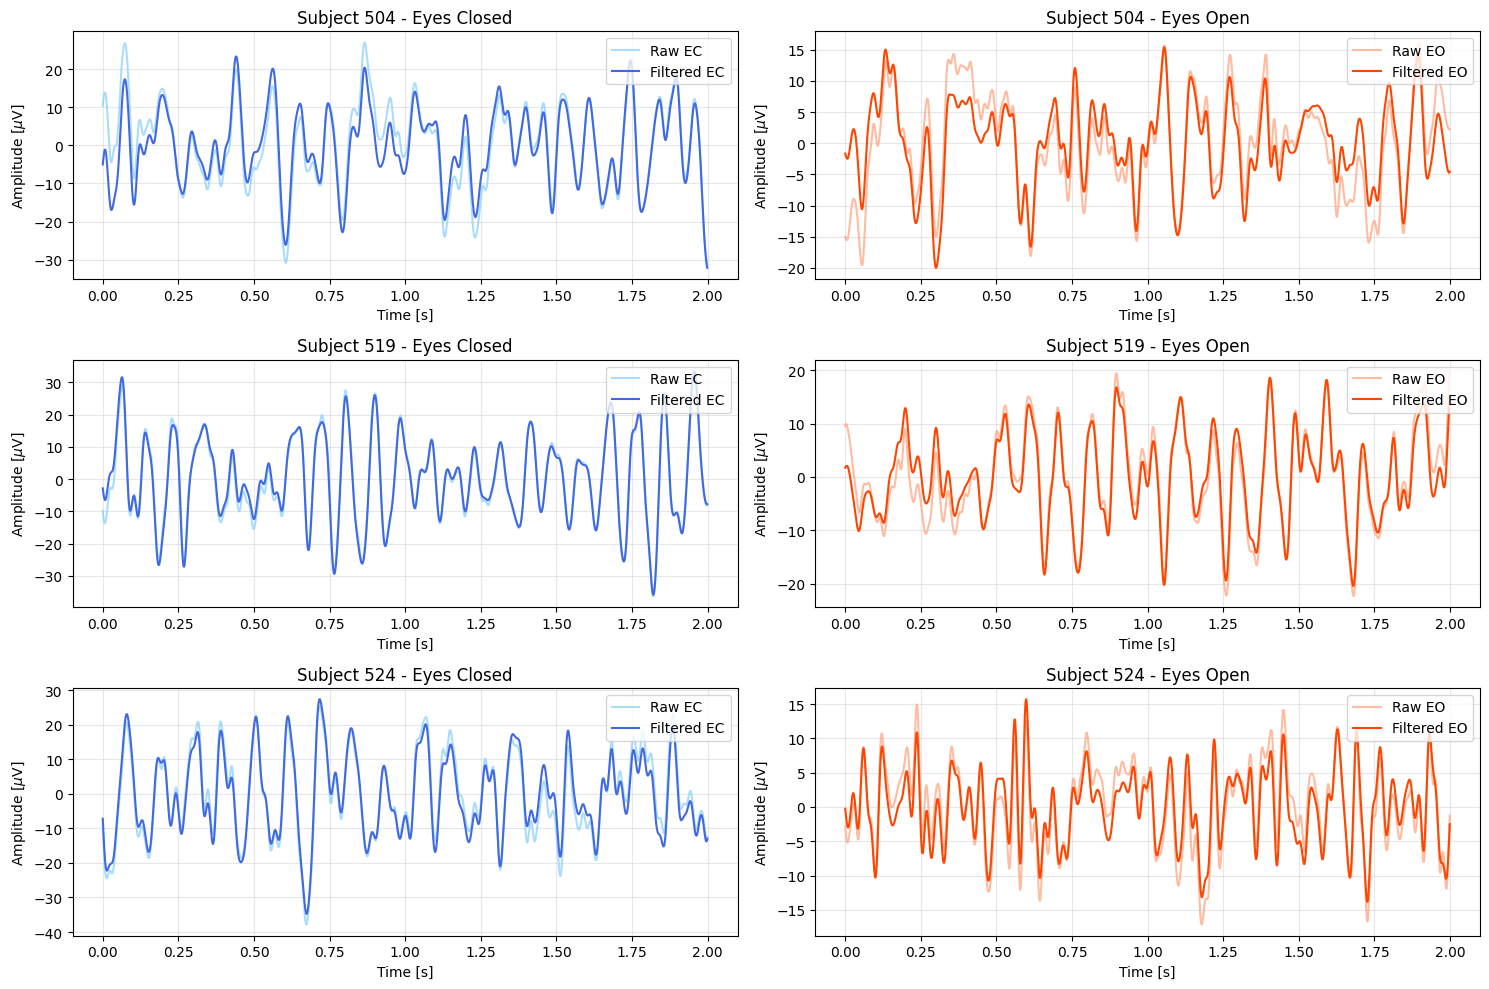

In [24]:
# Calculating low and high limits for the filtering, using nyquist frequency.
nyquist = 0.5 * fs
low = 2 / nyquist
high = 40 / nyquist
b, a = signal.butter(N=4, Wn=[low, high], btype='band')

# Calculating filtering for each subject.
for sub in subjects:
  data[sub]['EC_filtered'] = signal.filtfilt(b, a, data[sub]['EC'])
  data[sub]['EO_filtered'] = signal.filtfilt(b, a, data[sub]['EO'])

# 2-seconds window, according to instructions.
window_2s = int(2 * fs)

# Plotting results.
fig, axes = plt.subplots(3, 2, figsize=(15, 10))
for i, sub in enumerate(subjects):
    # Left column: Eyes Closed (Raw vs Filtered)
    axes[i, 0].plot(t[:window_2s], data[sub]['EC'][:window_2s], color='lightskyblue', label='Raw EC', alpha=0.7)
    axes[i, 0].plot(t[:window_2s], data[sub]['EC_filtered'][:window_2s], color='royalblue', label='Filtered EC', linewidth=1.5)
    axes[i, 0].set_title(f'Subject {sub} - Eyes Closed')
    axes[i, 0].set_xlabel('Time [s]')
    axes[i, 0].set_ylabel(r'Amplitude [$\mu$V]')
    axes[i, 0].legend(loc='upper right')
    axes[i, 0].grid(True, alpha=0.3)

    # Right column: Eyes Open (Raw vs Filtered)
    axes[i, 1].plot(t[:window_2s], data[sub]['EO'][:window_2s], color='lightsalmon', label='Raw EO', alpha=0.7)
    axes[i, 1].plot(t[:window_2s], data[sub]['EO_filtered'][:window_2s], color='orangered', label='Filtered EO', linewidth=1.5)
    axes[i, 1].set_title(f'Subject {sub} - Eyes Open')
    axes[i, 1].set_xlabel('Time [s]')
    axes[i, 1].set_ylabel(r'Amplitude [$\mu$V]')
    axes[i, 1].legend(loc='upper right')
    axes[i, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Part 3: Spectral Analysis and IAF
**3.1 - Power Spectrum using FFT**

In [25]:
def power_fft(signal, fs):
  """
  Computes the power spectrum using the Fast Fourier Transform (FFT).
  """
  N = len(signal)
  freqs = np.fft.rfftfreq(N, 1/fs)
  fft_vals = np.fft.rfft(signal)
  normalized_fft = fft_vals / N
  power = np.abs(normalized_fft)
  return freqs, power

**3.2 - Smoothed FFT**

In [26]:
from scipy.ndimage import gaussian_filter1d

def smooth_fft(power, sigma=3):
  """
  Smooths the FFT power spectrum using a moving average filter.
  """
  return gaussian_filter1d(power, sigma=sigma)

**3.3 - PSD using Welch**

In [27]:
def welch_psd(signal_data, fs, win_sec=4, overlap=2):
  """
  Estimates the power spectrum using the Welch method with a 4-seconds window and a 50% overlap.
  """
  nperseg = int(win_sec * fs)
  noverlap = int(nperseg // overlap)
  freqs, psd = signal.welch(signal_data, fs, window='hann', nperseg=nperseg, noverlap=noverlap)
  return freqs, psd

**3.4 - IAF (Individual Alpha Frequency)**

In [28]:
def find_iaf(freqs, power):
  """
  Finds the peak alpha frequency and its maximum power in the 7.5-12.5 Hz range.
  """
  alpha_mask = (freqs >= 7.5) & (freqs <= 12.5)
  alpha_freqs = freqs[alpha_mask]
  alpha_power = power[alpha_mask]

  max_idx = np.argmax(alpha_power)
  return alpha_freqs[max_idx], alpha_power[max_idx]

**Computing Calculations of All Functions**

In [29]:
from IPython.display import display

for sub in subjects:
    ec_sig = data[sub]['EC_filtered']
    eo_sig = data[sub]['EO_filtered']

    # 1. Calculate FFT.
    freqs_ec, power_ec = power_fft(ec_sig, fs)
    freqs_eo, power_eo = power_fft(eo_sig, fs)

    data[sub]['FFT_freqs_EC'], data[sub]['FFT_power_EC'] = freqs_ec, power_ec
    data[sub]['FFT_freqs_EO'], data[sub]['FFT_power_EO'] = freqs_eo, power_eo

    # 2. Calculate Smoothed FFT.
    data[sub]['Smooth_power_EC'] = smooth_fft(power_ec, sigma=3)
    data[sub]['Smooth_power_EO'] = smooth_fft(power_eo, sigma=3)

    # 3. Calculate Welch PSD.
    freqs_w_ec, pow_w_ec = welch_psd(ec_sig, fs, win_sec=4, overlap=2)
    freqs_w_eo, pow_w_eo = welch_psd(eo_sig, fs, win_sec=4, overlap=2)

    data[sub]['Welch_freqs_EC'], data[sub]['Welch_power_EC'] = freqs_w_ec, pow_w_ec
    data[sub]['Welch_freqs_EO'], data[sub]['Welch_power_EO'] = freqs_w_eo, pow_w_eo

    # 4. Find IAF for all methods and conditions.
    # FFT
    data[sub]['IAF_FFT_EC'] = find_iaf(freqs_ec, power_ec)
    data[sub]['IAF_FFT_EO'] = find_iaf(freqs_eo, power_eo)
    # Smoothed
    data[sub]['IAF_Smooth_EC'] = find_iaf(freqs_ec, data[sub]['Smooth_power_EC'])
    data[sub]['IAF_Smooth_EO'] = find_iaf(freqs_eo, data[sub]['Smooth_power_EO'])
    # Welch
    data[sub]['IAF_Welch_EC'] = find_iaf(freqs_w_ec, pow_w_ec)
    data[sub]['IAF_Welch_EO'] = find_iaf(freqs_w_eo, pow_w_eo)

# An empty list to print the IAF values.
table_data = []

for sub in subjects:
    # Extract freqs to EO condition.
    iaf_fft_eo = data[sub]['IAF_FFT_EO'][0]
    iaf_smooth_eo = data[sub]['IAF_Smooth_EO'][0]
    iaf_welch_eo = data[sub]['IAF_Welch_EO'][0]

    # Extract freqs to EC condition.
    iaf_fft_ec = data[sub]['IAF_FFT_EC'][0]
    iaf_smooth_ec = data[sub]['IAF_Smooth_EC'][0]
    iaf_welch_ec = data[sub]['IAF_Welch_EC'][0]

    # Adding EO line to the table.
    table_data.append({
        'Participant': sub,
        'Condition': 'EO',
        'Raw FFT [Hz]': f"{iaf_fft_eo:.2f}",
        'Smoothed FFT [Hz]': f"{iaf_smooth_eo:.2f}",
        'Welch PSD [Hz]': f"{iaf_welch_eo:.2f}"
    })

    # Adding EC line to the table.
    table_data.append({
        'Participant': sub,
        'Condition': 'EC',
        'Raw FFT [Hz]': f"{iaf_fft_ec:.2f}",
        'Smoothed FFT [Hz]': f"{iaf_smooth_ec:.2f}",
        'Welch PSD [Hz]': f"{iaf_welch_ec:.2f}"
    })

# Converting the list to a Pandas table.
df_iaf = pd.DataFrame(table_data)

# Removing the index column.
styled_df = df_iaf.style.hide(axis="index")
display(styled_df)

Participant,Condition,Raw FFT [Hz],Smoothed FFT [Hz],Welch PSD [Hz]
504,EO,9.22,11.02,11.00
504,EC,7.57,8.22,8.25
519,EO,10.02,10.05,10.00
519,EC,10.77,10.07,10.75
524,EO,12.12,8.95,9.00
524,EC,9.45,9.30,9.25


**Plotting all Results**

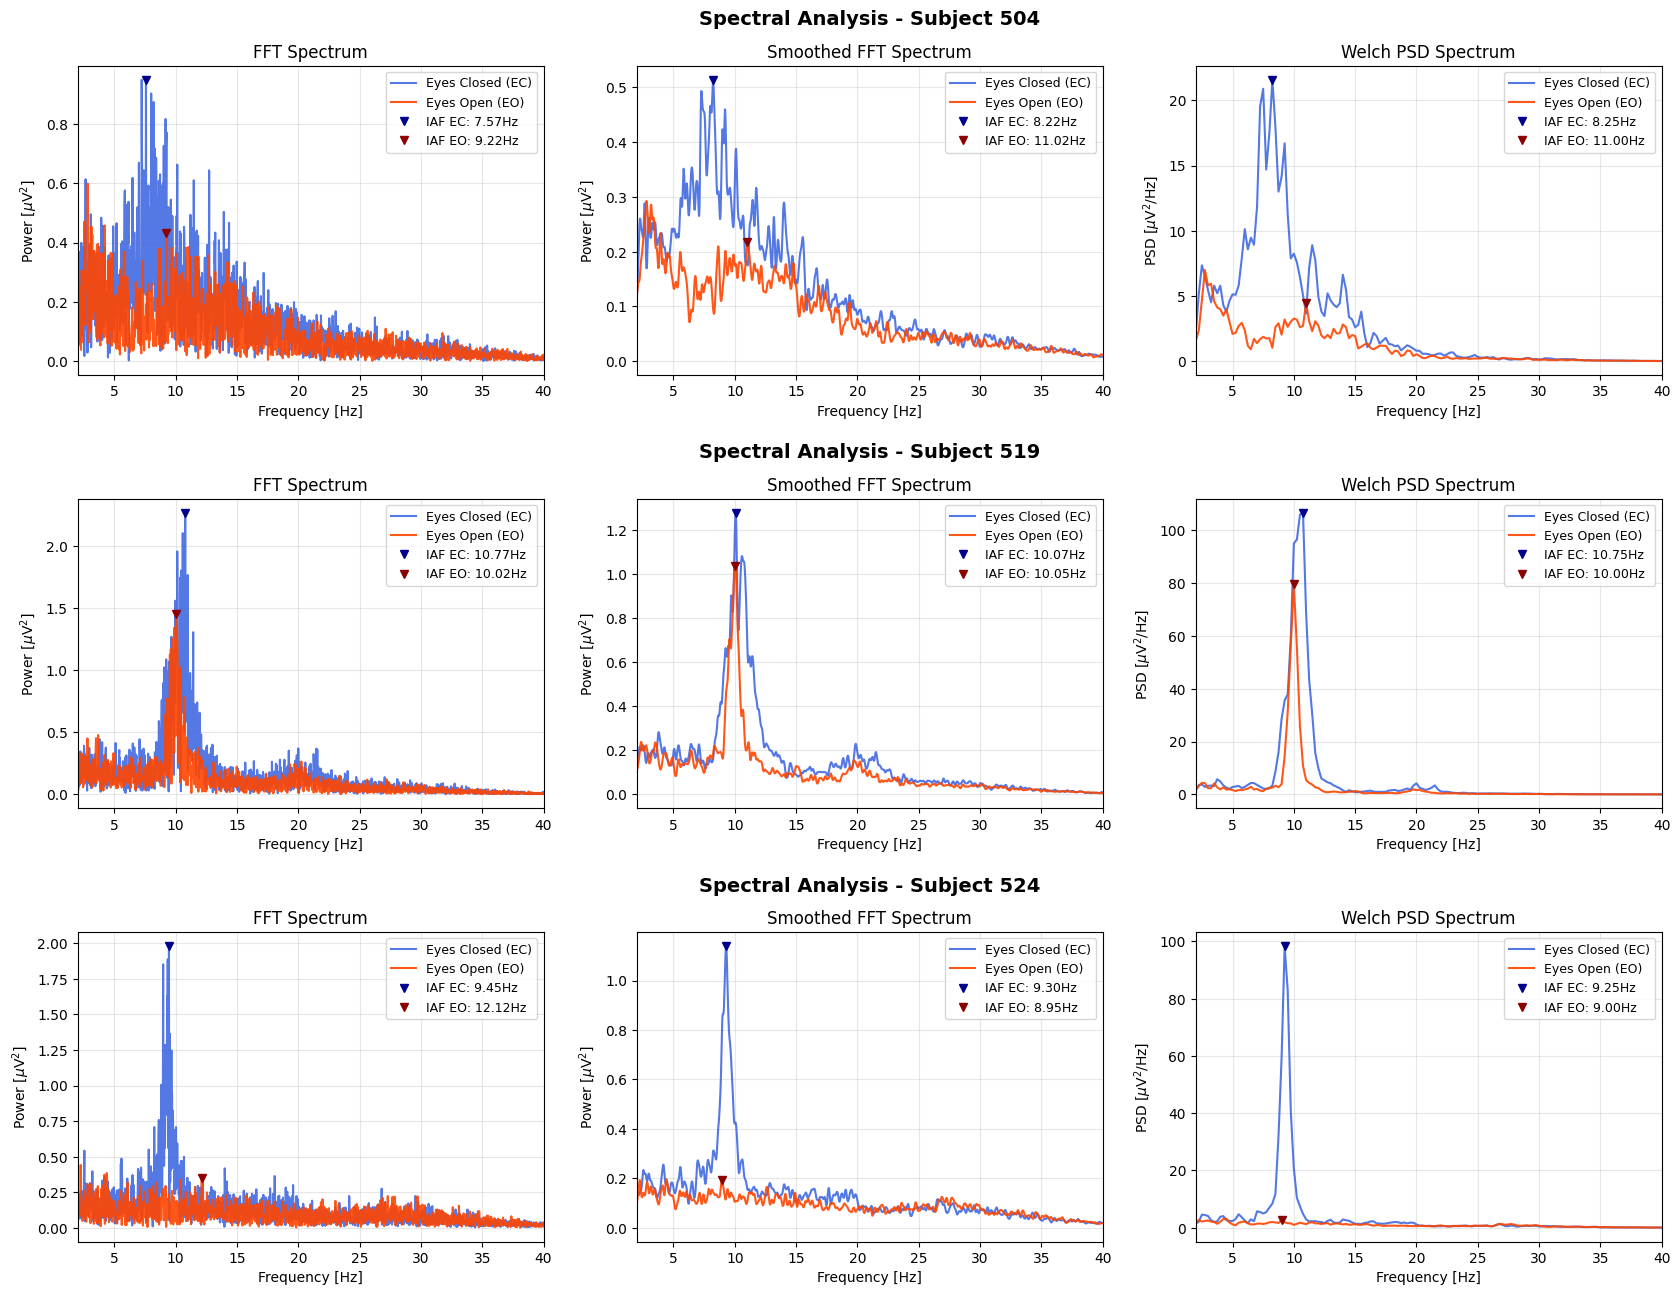

In [30]:
fig, axes = plt.subplots(3, 3, figsize=(18, 14))

for i, sub in enumerate(subjects):
  # Title for each subject.
  axes[i, 1].text(0.5, 1.12, f'Spectral Analysis - Subject {sub}', transform=axes[i, 1].transAxes,
                  ha='center', va='bottom', fontsize=14, fontweight='bold', color='black')

  # Extract IAF values for the legend
  iaf_f_fft_ec, iaf_p_fft_ec = data[sub]['IAF_FFT_EC']
  iaf_f_fft_eo, iaf_p_fft_eo = data[sub]['IAF_FFT_EO']

  iaf_f_sm_ec, iaf_p_sm_ec = data[sub]['IAF_Smooth_EC']
  iaf_f_sm_eo, iaf_p_sm_eo = data[sub]['IAF_Smooth_EO']

  iaf_f_w_ec, iaf_p_w_ec = data[sub]['IAF_Welch_EC']
  iaf_f_w_eo, iaf_p_w_eo = data[sub]['IAF_Welch_EO']

  # -- Column 1 (Index 0): FFT Power Spectrum --
  axes[i, 0].plot(data[sub]['FFT_freqs_EC'], data[sub]['FFT_power_EC'], label='Eyes Closed (EC)', color='royalblue', alpha=0.9)
  axes[i, 0].plot(data[sub]['FFT_freqs_EO'], data[sub]['FFT_power_EO'], label='Eyes Open (EO)', color='orangered', alpha=0.9)
  axes[i, 0].plot(iaf_f_fft_ec, iaf_p_fft_ec, 'v', color='darkblue', markersize=6, label=f'IAF EC: {iaf_f_fft_ec:.2f}Hz')
  axes[i, 0].plot(iaf_f_fft_eo, iaf_p_fft_eo, 'v', color='darkred', markersize=6, label=f'IAF EO: {iaf_f_fft_eo:.2f}Hz')
  axes[i, 0].set_title(f'FFT Spectrum')
  axes[i, 0].set_xlabel('Frequency [Hz]')
  axes[i, 0].set_xlim(2, 40)
  axes[i, 0].set_ylabel(r'Power [$\mu$V$^2$]')
  axes[i, 0].legend(loc='upper right', fontsize=9)
  axes[i, 0].grid(True, alpha=0.3)

  # -- Column 2 (Index 1): Smoothed FFT --
  axes[i, 1].plot(data[sub]['FFT_freqs_EC'], data[sub]['Smooth_power_EC'], label='Eyes Closed (EC)', color='royalblue', alpha=0.9)
  axes[i, 1].plot(data[sub]['FFT_freqs_EO'], data[sub]['Smooth_power_EO'], label='Eyes Open (EO)', color='orangered', alpha=0.9)
  axes[i, 1].plot(iaf_f_sm_ec, iaf_p_sm_ec, 'v', color='darkblue', markersize=6, label=f'IAF EC: {iaf_f_sm_ec:.2f}Hz')
  axes[i, 1].plot(iaf_f_sm_eo, iaf_p_sm_eo, 'v', color='darkred', markersize=6, label=f'IAF EO: {iaf_f_sm_eo:.2f}Hz')
  axes[i, 1].set_title(f'Smoothed FFT Spectrum')
  axes[i, 1].set_xlabel('Frequency [Hz]')
  axes[i, 1].set_xlim(2, 40)
  axes[i, 1].set_ylabel(r'Power [$\mu$V$^2$]')
  axes[i, 1].legend(loc='upper right', fontsize=9)
  axes[i, 1].grid(True, alpha=0.3)

  # -- Column 3 (Index 2): Welch PSD --
  axes[i, 2].plot(data[sub]['Welch_freqs_EC'], data[sub]['Welch_power_EC'], label='Eyes Closed (EC)', color='royalblue', alpha=0.9)
  axes[i, 2].plot(data[sub]['Welch_freqs_EO'], data[sub]['Welch_power_EO'], label='Eyes Open (EO)', color='orangered', alpha=0.9)
  axes[i, 2].plot(iaf_f_w_ec, iaf_p_w_ec, 'v', color='darkblue', markersize=6, label=f'IAF EC: {iaf_f_w_ec:.2f}Hz')
  axes[i, 2].plot(iaf_f_w_eo, iaf_p_w_eo, 'v', color='darkred', markersize=6, label=f'IAF EO: {iaf_f_w_eo:.2f}Hz')
  axes[i, 2].set_title(f'Welch PSD Spectrum')
  axes[i, 2].set_xlabel('Frequency [Hz]')
  axes[i, 2].set_xlim(2, 40)
  axes[i, 2].set_ylabel(r'PSD [$\mu$V$^2$/Hz]')
  axes[i, 2].legend(loc='upper right', fontsize=9)
  axes[i, 2].grid(True, alpha=0.3)

  # Shared label for axes X.
  if i == 2:
    axes[i, 0].set_xlabel('Frequency [Hz]')
    axes[i, 1].set_xlabel('Frequency [Hz]')
    axes[i, 2].set_xlabel('Frequency [Hz]')

plt.subplots_adjust(hspace=0.4, wspace=0.2, top=0.90, bottom=0.06, left=0.06, right=0.94)
plt.show()

### Part 4: Spectrogram
**4.1 - Computing Spectrogram**

In [31]:
from scipy.signal import spectrogram

# Defining parameters.
SPEC_WINDOW_SEC = 2
SPEC_OVERLAP_RATIO = 0.90

for sub in subjects:
    ec_sig = data[sub]['EC_filtered']
    eo_sig = data[sub]['EO_filtered']

    # Calculating the number of samples per wundow and overlap.
    nperseg_spec = int(SPEC_WINDOW_SEC * fs)
    noverlap_spec = int(nperseg_spec * SPEC_OVERLAP_RATIO)

    # Calculating the spectrogram.
    f_ec, t_ec, Sxx_ec = spectrogram(ec_sig, fs, window='hann', nperseg=nperseg_spec, noverlap=noverlap_spec)
    f_eo, t_eo, Sxx_eo = spectrogram(eo_sig, fs, window='hann', nperseg=nperseg_spec, noverlap=noverlap_spec)

    # Converting to dB.
    Sxx_ec_dB = 10 * np.log10(Sxx_ec + 1e-10)
    Sxx_eo_dB = 10 * np.log10(Sxx_eo + 1e-10)

    # Saving the results for plotting.
    data[sub]['Spec_f_EC'], data[sub]['Spec_t_EC'], data[sub]['Spec_Sxx_dB_EC'] = f_ec, t_ec, Sxx_ec_dB
    data[sub]['Spec_f_EO'], data[sub]['Spec_t_EO'], data[sub]['Spec_Sxx_dB_EO'] = f_eo, t_eo, Sxx_eo_dB

print("Spectrogram calculations completed.")

Spectrogram calculations completed.


**4.4 - Plotting**

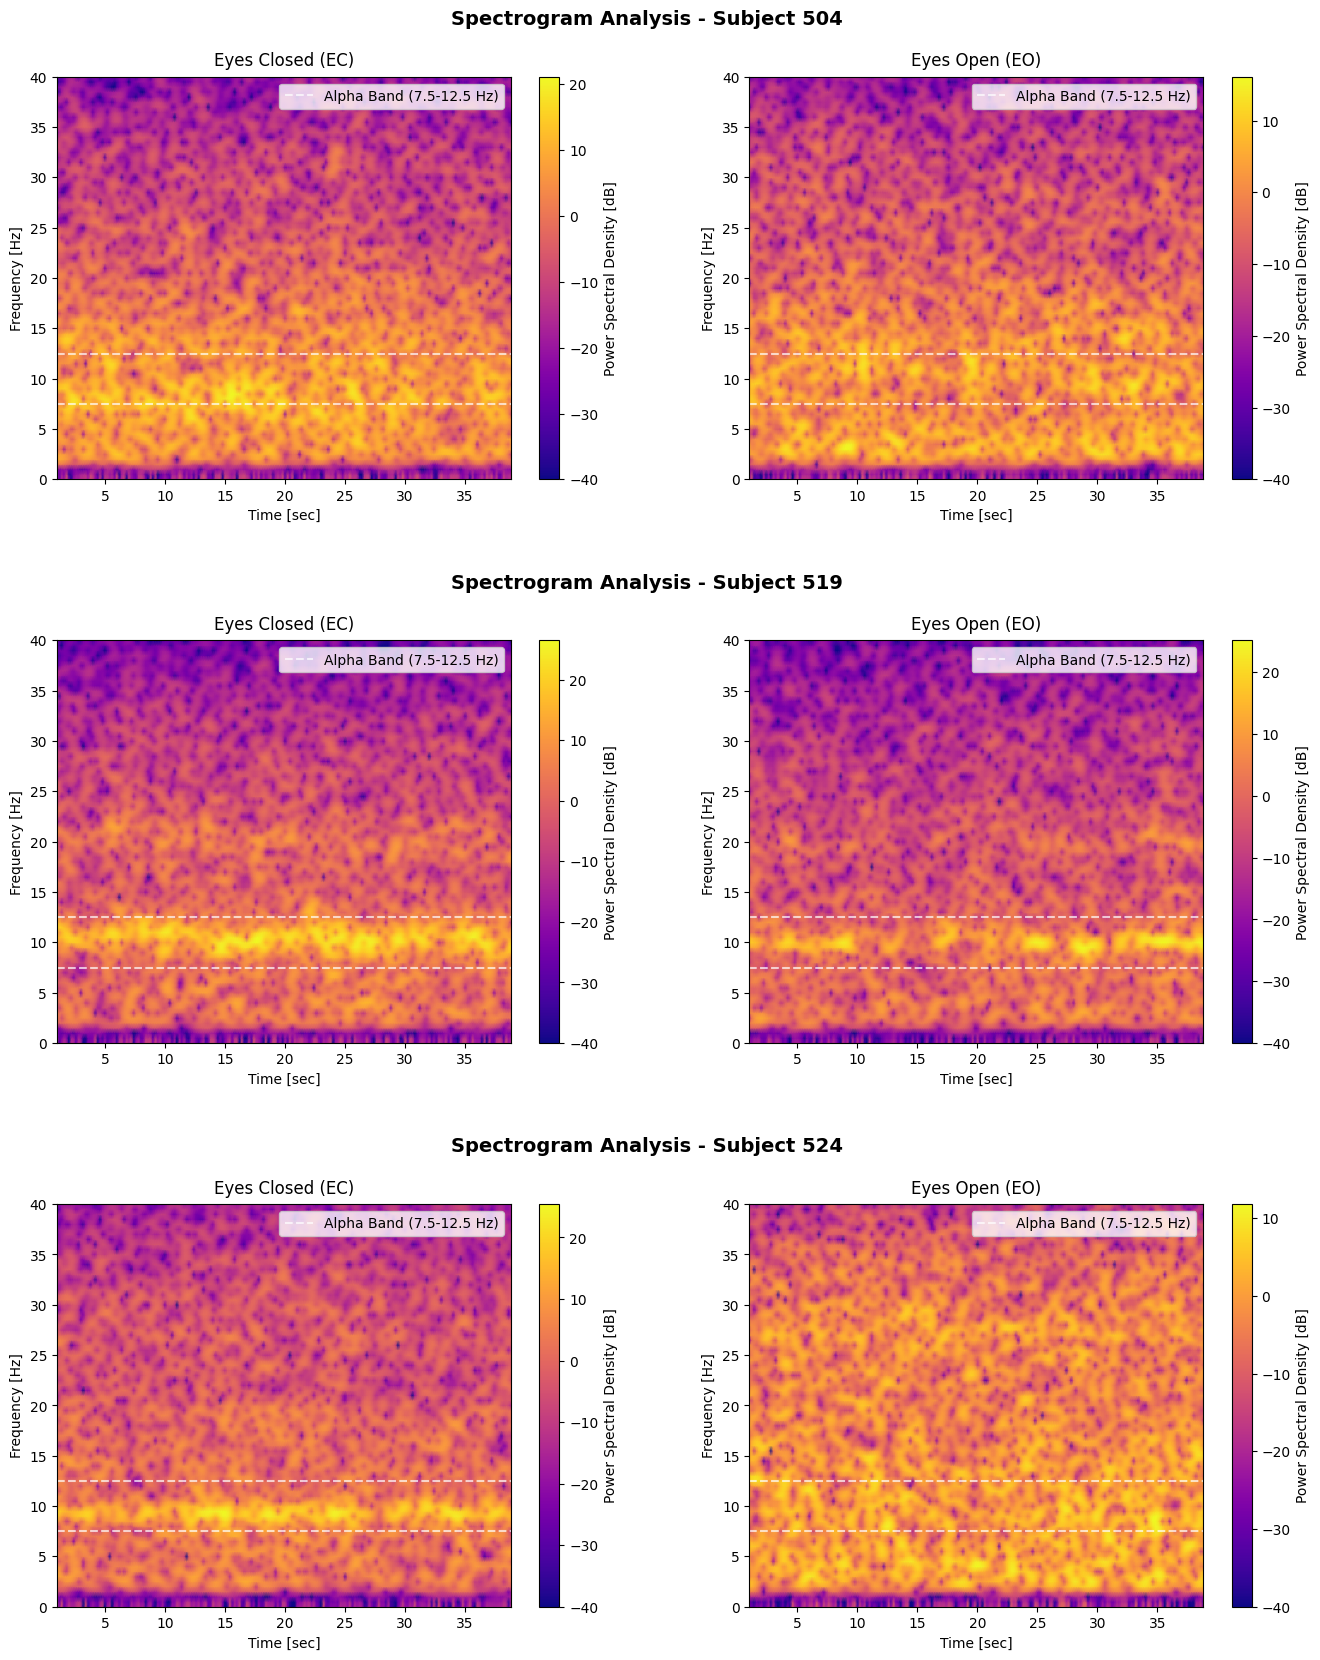

In [32]:
fig, axes = plt.subplots(3, 2, figsize=(15, 18))

for i, sub in enumerate(subjects):
    # Extracting the calculation results.
    f_ec = data[sub]['Spec_f_EC']
    t_ec = data[sub]['Spec_t_EC']
    Sxx_ec_dB = data[sub]['Spec_Sxx_dB_EC']

    f_eo = data[sub]['Spec_f_EO']
    t_eo = data[sub]['Spec_t_EO']
    Sxx_eo_dB = data[sub]['Spec_Sxx_dB_EO']

    # -- Column 1: Eyes Closed (EC) --
    im1 = axes[i, 0].pcolormesh(t_ec, f_ec, Sxx_ec_dB, shading='gouraud', cmap='plasma', vmin=-40)
    axes[i, 0].set_title('Eyes Closed (EC)', pad=8)
    axes[i, 0].set_xlabel('Time [sec]')
    axes[i, 0].set_ylabel('Frequency [Hz]')
    axes[i, 0].axhline(y=7.5, color='white', linestyle='--', alpha=0.7, label='Alpha Band (7.5-12.5 Hz)')
    axes[i, 0].axhline(y=12.5, color='white', linestyle='--', alpha=0.7)
    axes[i, 0].set_ylim(0, 40)
    axes[i, 0].legend(loc='upper right')
    cbar1 = fig.colorbar(im1, ax=axes[i, 0])
    cbar1.set_label('Power Spectral Density [dB]')

    # -- Column 2: Eyes Open (EO) --
    im2 = axes[i, 1].pcolormesh(t_eo, f_eo, Sxx_eo_dB, shading='gouraud', cmap='plasma', vmin=-40)
    axes[i, 1].set_title('Eyes Open (EO)', pad=8)
    axes[i, 1].set_xlabel('Time [sec]')
    axes[i, 1].set_ylabel('Frequency [Hz]')
    axes[i, 1].axhline(y=7.5, color='white', linestyle='--', alpha=0.7, label='Alpha Band (7.5-12.5 Hz)')
    axes[i, 1].axhline(y=12.5, color='white', linestyle='--', alpha=0.7)
    axes[i, 1].set_ylim(0, 40)
    axes[i, 1].legend(loc='upper right')
    cbar2 = fig.colorbar(im2, ax=axes[i, 1])
    cbar2.set_label('Power Spectral Density [dB]')

    axes[i, 0].text(1.3, 1.12, f'Spectrogram Analysis - Subject {sub}', transform=axes[i, 0].transAxes,
                    ha='center', va='bottom', fontsize=14, fontweight='bold', color='black')

plt.subplots_adjust(hspace=0.4, wspace=0.22, top=0.91, bottom=0.06, left=0.08, right=0.92)
plt.show()

### Part 5: Alpha Reconstruction Using IFFT

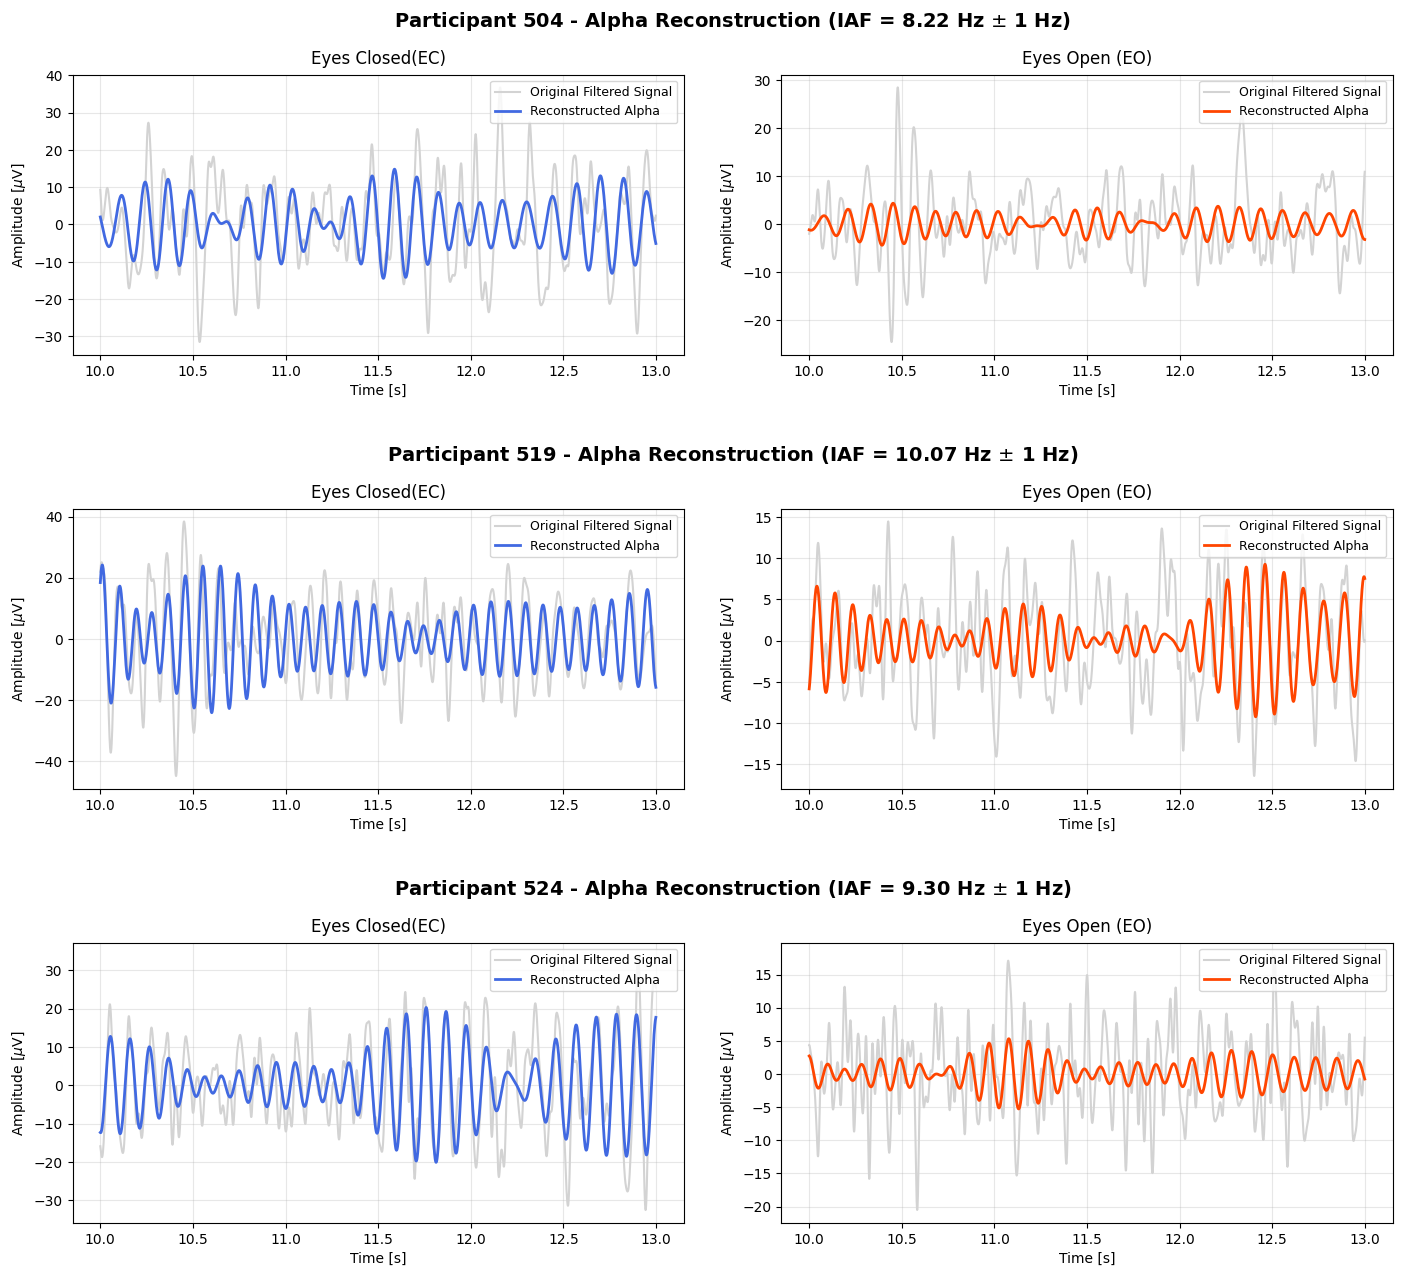

In [33]:
def recons_alpha(signal, fs, iaf_freq):
    """
    Reconstructs the alpha band signal using Inverse FFT.
    Keeps only the frequencies within IAF +/- 1 Hz and sets the rest to zero.
    """
    N = len(signal)

    # Compute the FFT of the signal.
    freqs = np.fft.rfftfreq(N, 1/fs)
    fft_vals = np.fft.rfft(signal)

    # Define an individual alpha band (IAF +/- 1 Hz).
    lower_bound = iaf_freq - 1.0
    upper_bound = iaf_freq + 1.0
    alpha_mask = (np.abs(freqs) >= lower_bound) & (np.abs(freqs) <= upper_bound)

    # Keep only frequencies within this range, set others to zero.
    fft_filtered = np.copy(fft_vals)
    fft_filtered[~alpha_mask] = 0

    # Reconstruct the signal using IFFT.
    recons_signal = np.fft.irfft(fft_filtered, n=N).real
    return recons_signal

# Defining an appropriate time window for visualization.
START_SEC = 10
END_SEC = 13
start_idx = int(START_SEC * fs)
end_idx = int(END_SEC * fs)
t_window = np.arange(start_idx, end_idx) / fs

# Plotting the reconstructed signal for each participant.
fig, axes = plt.subplots(3, 2, figsize=(15, 14))

for i, sub in enumerate(subjects):
    ec_sig = data[sub]['EC_filtered']
    eo_sig = data[sub]['EO_filtered']

    # Choose the most reliable IAF estimate (Smoothed EC).
    best_iaf = data[sub]['IAF_Smooth_EC'][0]

    # Reconstruct the signal for both conditions.
    recon_ec = recons_alpha(ec_sig, fs, best_iaf)
    recon_eo = recons_alpha(eo_sig, fs, best_iaf)

    # -- Column 1: Eyes Closed (EC) --
    axes[i, 0].plot(t_window, ec_sig[start_idx:end_idx], label='Original Filtered Signal', color='lightgray', linewidth=1.5)
    axes[i, 0].plot(t_window, recon_ec[start_idx:end_idx], label='Reconstructed Alpha', color='royalblue', linewidth=2)
    axes[i, 0].set_title(f'Eyes Closed(EC)', pad=8)
    axes[i, 0].set_xlabel('Time [s]')
    axes[i, 0].set_ylabel(r'Amplitude [$\mu$V]')
    axes[i, 0].legend(loc='upper right', fontsize=9)
    axes[i, 0].grid(True, alpha=0.3)

    # -- Column 2: Eyes Open (EO) --
    axes[i, 1].plot(t_window, eo_sig[start_idx:end_idx], label='Original Filtered Signal', color='lightgray', linewidth=1.5)
    axes[i, 1].plot(t_window, recon_eo[start_idx:end_idx], label='Reconstructed Alpha', color='orangered', linewidth=2)
    axes[i, 1].set_title(f'Eyes Open (EO)', pad=8)
    axes[i, 1].set_xlabel('Time [s]')
    axes[i, 1].set_ylabel(r'Amplitude [$\mu$V]')
    axes[i, 1].legend(loc='upper right', fontsize=9)
    axes[i, 1].grid(True, alpha=0.3)

    # Add a shared title for each participant row, exactly in the center.
    axes[i, 0].text(1.08, 1.15, rf'Participant {sub} - Alpha Reconstruction (IAF = {best_iaf:.2f} Hz $\pm$ 1 Hz)', transform=axes[i, 0].transAxes,
                    ha='center', va='bottom', fontsize=14, fontweight='bold', color='black')

# Adjust layout to prevent overlapping text and graphs.
plt.subplots_adjust(hspace=0.55, wspace=0.16, top=0.88, bottom=0.06, left=0.06, right=0.94)
plt.show()